# 2) notebook 2nd 

## Image Generation with Pre-trained Models (Stable Diffusion + KerasCV)
**Author:** [Ajim Mujawar]  
**Task 02 - Generative AI**

Goal: use a pre-trained text-to-image model (Stable Diffusion) to create images from text prompts, understand how it works, and explore the parameters that control it.

> Run on a GPU runtime (Colab: Runtime -> Change runtime type -> T4 GPU). On CPU it is extremely slow.

In [1]:

!nvidia-smi


Tue Oct 20 09:03:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:

!pip install -q diffusers transformers accelerate safetensors



In [4]:

%pip install -q --upgrade diffusers transformers accelerate safetensors
%pip uninstall -y torchao


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 106.4 MB/s eta 0:00:00
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [8]:

import sys
import importlib.util
import importlib.metadata as metadata

print("Python:", sys.version)
print("Python executable:", sys.executable)

spec = importlib.util.find_spec("torchao")
print("TorchAO module:", spec.origin if spec else "Not found")

for package in ["torch", "torchao", "diffusers", "transformers"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: not installed")

import torch
print("GPU available:", torch.cuda.is_available())


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Python executable: /usr/bin/python3
TorchAO module: /usr/local/lib/python3.13/dist-packages/torchao/__init__.py
torch: 2.11.0+cu130
torchao: not installed
diffusers: 0.41.0
transformers: 5.20.2
GPU available: True


In [9]:

%pip install --force-reinstall --no-cache-dir \
  "diffusers==0.35.1" \
  "transformers==4.46.3" \
  "accelerate==1.2.1" \
  "safetensors>=0.4.3"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 226.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 135.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 283.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 166.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 99.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 252.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.4/336.4 kB 419.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 430.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 206.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 260.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 378.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.6/801.6 kB 364.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:

import importlib.metadata as md

for package in ["torch", "torchvision", "torchaudio", "diffusers", "transformers"]:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: not installed")


torch: 2.14.1
torchvision: 0.26.0+cu130
torchaudio: 2.11.0+cu130
diffusers: 0.35.1
transformers: 4.46.3


In [3]:

%pip install --force-reinstall --no-deps \
  torchvision==0.26.0 \
  --index-url https://download.pytorch.org/whl/cu130


Looking in indexes: https://download.pytorch.org/whl/cu130
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 61.3 MB/s eta 0:00:00
  Attempting uninstall: torchvision
    Found existing installation: torchvision 0.26.0+cu130
    Uninstalling torchvision-0.26.0+cu130:
      Successfully uninstalled torchvision-0.26.0+cu130


In [5]:

import torch
import diffusers

print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch: 2.11.0+cu130
Diffusers: 0.41.0
GPU available: True


In [5]:

!pip show torch torchvision torchaudio
!pip check


Name: torch
Version: 2.14.1
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License: 
Location: /usr/local/lib/python3.13/dist-packages
Requires: cuda-bindings, cuda-toolkit, filelock, fsspec, jinja2, networkx, nvidia-cudnn-cu13, nvidia-cusparselt-cu13, nvidia-nccl-cu13, nvidia-nvshmem-cu13, setuptools, sympy, triton, typing-extensions
Required-by: accelerate, fastai, peft, sentence-transformers, timm, torchdata, torchvision
---
Name: torchvision
Version: 0.26.0+cu130
Summary: image and video datasets and models for torch deep learning
Home-page: https://github.com/pytorch/vision
Author: PyTorch Core Team
Author-email: soumith@pytorch.org
License: BSD
Location: /usr/local/lib/python3.13/dist-packages
Requires: numpy, pillow, torch
Required-by: fastai, timm
---
Name: torchaudio
Version: 2.11.0+cu130
Summary: An audio package for PyTorch
Home-page: https://github.

In [6]:

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")


PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [7]:

%pip install -q diffusers==0.35.1 transformers==4.46.3 accelerate==1.2.1 safetensors


In [10]:

import sys
import importlib.metadata as md

print("Python:", sys.version)

for package in ["torch", "torchvision", "torchaudio", "diffusers", "transformers"]:
    try:
        print(package, md.version(package))
    except md.PackageNotFoundError:
        print(package, "not installed")

import torch
print("CUDA available:", torch.cuda.is_available())


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
torch 2.14.1
torchvision 0.26.0+cu130
torchaudio 2.11.0+cu130
diffusers 0.35.1
transformers 4.46.3
CUDA available: True


In [11]:

%pip install --force-reinstall \
  torch==2.11.0 \
  torchvision==0.26.0 \
  torchaudio==2.11.0 \
  --index-url https://download.pytorch.org/whl/cu130


Looking in indexes: https://download.pytorch.org/whl/cu130
  Using cached https://download-r2.pytorch.org/whl/cu130/torchvision-0.26.0%2Bcu130-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (5.5 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.1/366.1 MB 25.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.9/169.9 MB 96.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.5/196.5 MB 90.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 101.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 70.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 151.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 100.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 196.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 145.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.5/59.5 MB 110.8 MB/s eta 0

In [1]:

import torch
import torchvision
import torchaudio

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("TorchAudio:", torchaudio.__version__)
print("GPU available:", torch.cuda.is_available())

from diffusers import StableDiffusionPipeline
print("Stable Diffusion import successful!")


PyTorch: 2.11.0+cu130
TorchVision: 0.26.0+cu130
TorchAudio: 2.11.0+cu130
GPU available: True
Stable Diffusion import successful!


In [2]:

import torch
from diffusers import StableDiffusionPipeline

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")

print("Stable Diffusion model loaded successfully!")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

merges.txt: 0.00B [00:00, ?B/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

... (9 outputs left out)

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Stable Diffusion model loaded successfully!


  0%|          | 0/25 [00:00<?, ?it/s]

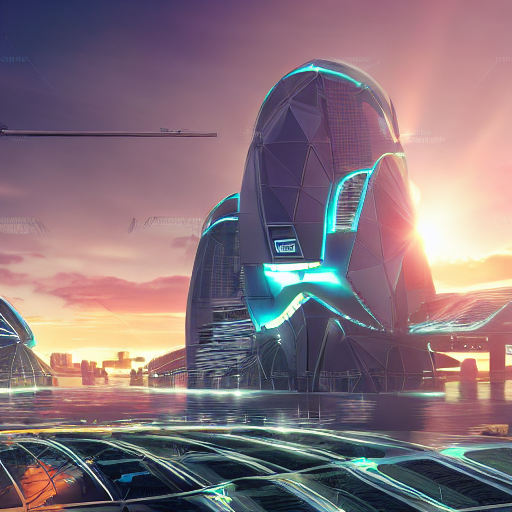

In [3]:

from IPython.display import display

prompt = (
    "A futuristic smart city at sunset, "
    "beautiful architecture, cinematic lighting, "
    "high detail, digital art"
)

image = pipe(
    prompt,
    num_inference_steps=25,
    guidance_scale=7.5
).images[0]

display(image)


In [4]:

image.save("stable_diffusion_output.png")

from google.colab import files
files.download("stable_diffusion_output.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  0%|          | 0/25 [00:00<?, ?it/s]

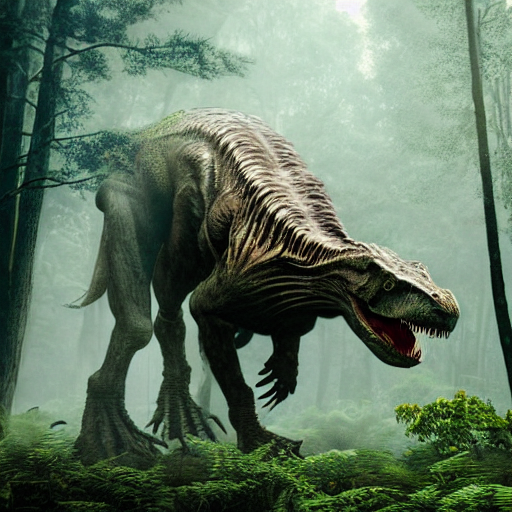

In [5]:

from IPython.display import display

prompt = (
    "A photorealistic Tyrannosaurus rex (T-Rex) walking through a dense, misty prehistoric forest, towering ancient trees, lush green ferns, soft sunlight filtering through the fog, "
    "realistic scaly skin texture, muscular body, detailed teeth and claws, wet forest floor, atmospheric lighting, cinematic composition, natural colors, ultra-detailed wildlife photography, "
    "sharp focus, 8K quality"
)

image = pipe(
    prompt,
    num_inference_steps=25,
    guidance_scale=7.5
).images[0]

display(image)


In [7]:

image.save("stable_diffusion_output.png")

from google.colab import files
files.download("stable_diffusion_output.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  0%|          | 0/25 [00:00<?, ?it/s]

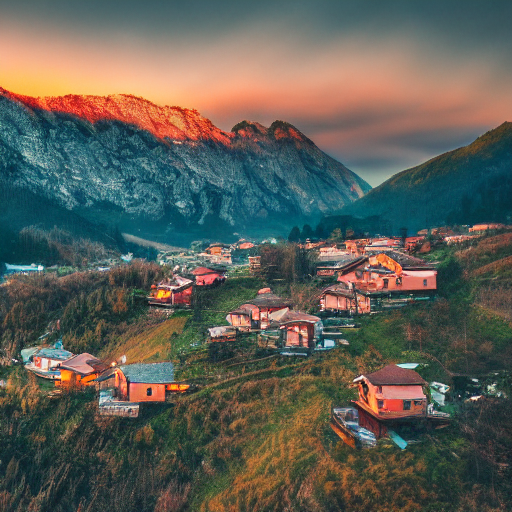

In [8]:

from IPython.display import display

prompt = (
    "A peaceful mountain village at sunrise, cinematic photography"
)

image = pipe(
    prompt,
    num_inference_steps=25,
    guidance_scale=7.5
).images[0]

display(image)


In [9]:

image.save("stable_diffusion_output.png")

from google.colab import files
files.download("stable_diffusion_output.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>